# CRISP-DM | Predicting international soccer results before kickoff

Estimate win, draw, and loss probabilities for men's national teams. A match preview writer can use the probabilities as a historical comparison.

[Dataset on Kaggle](https://www.kaggle.com/datasets/martj42/international-football-results-from-1872-to-2017)

Use a standard CPU runtime and run the cells in order.

Methodology reference: [IBM CRISP-DM](https://www.ibm.com/docs/en/spss-modeler/saas?topic=dm-crisp-help-overview). Kaggle snapshot version: 138.

## Setup

Download the Kaggle archive, check the selected CSVs against their SHA-256 fingerprints, and report the package versions. The fingerprints protect the analysis against changes to the source files.

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
from zipfile import ZipFile
from io import BytesIO
import hashlib
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from importlib.metadata import version

KAGGLE_DATASET = 'martj42/international-football-results-from-1872-to-2017'
KAGGLE_VERSION = 138
EXPECTED_SHA256 = {'results.csv': 'b38434f8f74cd9faacb269eb1c97760fc2dfac43fcb211779e0bd2cbb48f89e3'}
ARTIFACTS = Path(os.environ.get("PROJECT_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)


def load_kaggle_tables():
    archive_path = os.environ.get("PROJECT_DATA_ZIP")
    if archive_path:
        archive = Path(archive_path).read_bytes()
    else:
        url = f"https://www.kaggle.com/api/v1/datasets/download/{KAGGLE_DATASET}?datasetVersionNumber={KAGGLE_VERSION}"
        with urlopen(Request(url, headers={"User-Agent": "CMPE255-notebook/1.0"}), timeout=120) as response:
            archive = response.read()
    tables = {}
    with ZipFile(BytesIO(archive)) as zipped:
        for filename, expected in EXPECTED_SHA256.items():
            content = zipped.read(filename)
            actual = hashlib.sha256(content).hexdigest()
            if actual != expected:
                raise ValueError(f"{filename} changed. Use the archived Kaggle version described in the README.")
            tables[filename] = pd.read_csv(BytesIO(content), na_values=[r"\N"])
    return tables


def save_json(filename, payload):
    (ARTIFACTS / filename).write_text(json.dumps(payload, indent=2) + "\n")


tables = load_kaggle_tables()
print("Python", sys.version.split()[0])
print({name: version(name) for name in ("pandas", "numpy", "scikit-learn", "matplotlib")})
print({name: df.shape for name, df in tables.items()})
print("Kaggle snapshot:", KAGGLE_VERSION)

Python 3.14.7
{'pandas': '3.1.1', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}
{'results.csv': (49945, 9)}
Kaggle snapshot: 138


## 1. Business understanding

The question is whether prior results and venue improve on the overall frequency of each outcome. We predict from the perspective of the listed home team. A neutral venue means that the home label marks the order of teams in the data.

Log loss penalizes confident errors in probabilities. Macro F1 gives each outcome the same weight when scoring hard predictions. Use log loss as the primary criterion and report macro F1 to reveal performance on draws.

## 2. Data understanding

One row describes one international match. The scores define the target, and they exclude shootouts. The date, team names, and neutral venue flag inform the prediction. Tournament type supports exploration.

In [2]:
matches = tables["results.csv"]
preview_columns = ["date", "home_team", "away_team", "home_score", "away_score", "neutral"]
display(matches[preview_columns].tail(5))
display(matches[preview_columns].isna().sum().rename("missing").to_frame())

,date,home_team,away_team,home_score,away_score,neutral
49940,2026-10-06,Belize,French Guiana,0,1,False
49941,2026-10-06,Turks and Caicos Islands,Montserrat,1,4,False
49942,2026-10-06,Antigua and Barbuda,Aruba,3,2,False
49943,2026-10-06,Saint Martin,Bahamas,6,0,True
49944,2026-10-06,Saudi Arabia,United Arab Emirates,2,0,False


,missing
date,0
home_team,0
away_team,0
home_score,0
away_score,0
neutral,0


outcome,Draw,Loss,Win
neutral,,,
False,0.234,0.258,0.507
True,0.236,0.337,0.427


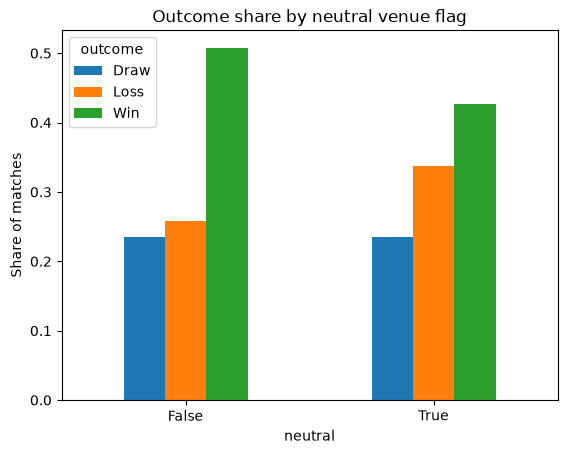

In [3]:
matches = matches.dropna(subset=preview_columns).drop_duplicates(subset=preview_columns).copy()
matches["date"] = pd.to_datetime(matches["date"])
matches = matches.loc[matches["date"].dt.year.between(1990, 2025)].sort_values("date")
matches["outcome"] = np.select(
    [matches.home_score.gt(matches.away_score), matches.home_score.lt(matches.away_score)],
    ["Win", "Loss"], default="Draw"
)
venue_mix = pd.crosstab(matches.neutral, matches.outcome, normalize="index")
display(venue_mix.round(3))
venue_mix.plot.bar(rot=0, title="Outcome share by neutral venue flag", ylabel="Share of matches")
plt.show()

## 3. Data preparation

Elo is a rating that updates after each match. Both teams start at 1,500. The update gives a larger reward when a lower-rated team wins. We use 1990–1999 as a warm-up period and derive features from earlier dates only. Each match on the same date sees the ratings as they stood at the start of that date. Validation and test ratings can incorporate completed matches on earlier dates because those results were available at prediction time.

In [4]:
from collections import defaultdict

FEATURES = ["elo_difference", "neutral"]
ratings = defaultdict(lambda: 1500.0)
rows = []
for date, day in matches.groupby("date", sort=True):
    changes = defaultdict(float)
    for match in day.itertuples():
        difference = ratings[match.home_team] - ratings[match.away_team]
        expected = 1 / (1 + 10 ** (-difference / 400))
        actual = {"Win": 1.0, "Draw": 0.5, "Loss": 0.0}[match.outcome]
        rows.append((date, match.home_team, match.away_team, difference, int(match.neutral), match.outcome))
        adjustment = 20 * (actual - expected)
        changes[match.home_team] += adjustment
        changes[match.away_team] -= adjustment
    for team, change in changes.items():
        ratings[team] += change

features = pd.DataFrame(rows, columns=["date", "home", "away", *FEATURES, "outcome"])
display(features.tail(5))

,date,home,away,elo_difference,neutral,outcome
32015,2025-12-30,Botswana,DR Congo,-191.172233,1,Loss
32016,2025-12-31,Sudan,Burkina Faso,-162.732184,1,Loss
32017,2025-12-31,Gabon,Ivory Coast,-157.162599,1,Loss
32018,2025-12-31,Equatorial Guinea,Algeria,-307.833821,1,Loss
32019,2025-12-31,Mozambique,Cameroon,-149.667842,1,Loss


In [5]:
year = features.date.dt.year
train = features.loc[year.between(2000, 2018)]
validation = features.loc[year.between(2019, 2022)]
test = features.loc[year.between(2023, 2025)]
assert train.date.max() < validation.date.min() < validation.date.max() < test.date.min()
display(pd.Series({"train": len(train), "validation": len(validation), "test": len(test)}))

train         18184
validation     3597
test           3297
dtype: int64

## 4. Modeling

A baseline is a simple point of comparison. Here it predicts the same probabilities for every match from the training outcome frequencies. Multiclass logistic regression uses the Elo difference and venue flag to estimate three probabilities. We compare three regularization strengths on the validation period and then refit the chosen model with training and validation data.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def soccer_model(strength):
    return make_pipeline(StandardScaler(), LogisticRegression(C=strength, max_iter=1000))


validation_scores = {}
for strength in (0.1, 1.0, 10.0):
    candidate = soccer_model(strength).fit(train[FEATURES], train.outcome)
    validation_scores[strength] = log_loss(validation.outcome, candidate.predict_proba(validation[FEATURES]), labels=candidate.classes_)
selected_strength = min(validation_scores, key=validation_scores.get)
development = pd.concat([train, validation])
model = soccer_model(selected_strength).fit(development[FEATURES], development.outcome)
baseline = DummyClassifier(strategy="prior").fit(development[FEATURES], development.outcome)
display(pd.Series(validation_scores, name="validation_log_loss"))
print("Selected C:", selected_strength)

0.1     0.865348
1.0     0.865301
10.0    0.865297
Name: validation_log_loss, dtype: float64

Selected C: 10.0


## 5. Evaluation

The test period estimates performance on future matches. Read log loss and macro F1 together. A draw can receive a useful probability even when it is rarely the most likely outcome. Review the confusion matrix to see which classes the model predicts.

In [7]:
scores = {}
for label, estimator in {"Training frequencies": baseline, "Elo and venue": model}.items():
    probabilities = estimator.predict_proba(test[FEATURES])
    predictions = estimator.predict(test[FEATURES])
    scores[label] = {
        "log_loss": log_loss(test.outcome, probabilities, labels=estimator.classes_),
        "macro_f1": f1_score(test.outcome, predictions, average="macro"),
    }
display(pd.DataFrame(scores).T.round(4))
matrix = confusion_matrix(test.outcome, model.predict(test[FEATURES]), labels=model.classes_)
display(pd.DataFrame(matrix, index=model.classes_, columns=model.classes_).rename_axis("Actual"))
save_json("evaluation.json", {"test_matches": len(test), "selected_C": selected_strength, "metrics": scores, "labels": model.classes_.tolist(), "confusion_matrix": matrix.tolist()})

,log_loss,macro_f1
Training frequencies,1.0540,0.2134
Elo and venue,0.8765,0.4423


,Draw,Loss,Win
Actual,,,
Draw,0,278,475
Loss,0,634,358
Win,0,199,1353


In [8]:
segment_rows = []
for venue, group in test.groupby("neutral"):
    p = model.predict_proba(group[FEATURES])
    segment_rows.append({
        "venue": "Neutral" if venue else "Non-neutral",
        "matches": len(group),
        "log_loss": log_loss(group.outcome, p, labels=model.classes_),
    })
display(pd.DataFrame(segment_rows).round(4))
draw_row = list(model.classes_).index("Draw")
print("True draws:", matrix[draw_row].sum(), "| correctly predicted draws:", matrix[draw_row, draw_row])

,venue,matches,log_loss
0,Non-neutral,2219,0.8528
1,Neutral,1078,0.9254


True draws: 753 | correctly predicted draws: 0


The model assigns probability to draws, but it never ranks a draw first on the test set. Treat it as a match preview aid. Assess it separately before using hard predictions or extending the analysis to other competitions.

## 6. Deployment

The prediction demo runs in Colab. The release artifact contains the fitted coefficients, scaling values, outcome labels, and team ratings. Inference reads only the artifact. It does not read match data or retrain the model.

For a fresh Colab session, download prediction_model.json from the project folder in GitHub. Upload it to Colab, change the final cell's artifact path to Path("prediction_model.json"), and run that cell by itself. The cell reports the date of the rating snapshot. Use the demo for matchups after that date. As more results arrive, rerun the notebook and compare performance on a new held-out period before replacing the artifact.

In [9]:
scaler, classifier = model.steps[0][1], model.steps[1][1]
save_json("prediction_model.json", {
    "classes": classifier.classes_.tolist(),
    "feature_order": FEATURES,
    "mean": scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),
    "coefficients": classifier.coef_.tolist(),
    "intercepts": classifier.intercept_.tolist(),
    "ratings": dict(ratings),
    "rating_snapshot": str(matches.date.max().date()),
})

In [10]:
# This cell also works by itself in a new runtime.
import json
from pathlib import Path
import numpy as np

artifact_path = Path("artifacts/prediction_model.json")
if "ARTIFACTS" in globals():
    artifact_path = ARTIFACTS / "prediction_model.json"
release = json.loads(artifact_path.read_text())


def predict_match(home_team, away_team, neutral_venue):
    if home_team == away_team:
        raise ValueError("Choose two different teams.")
    available_ratings = release["ratings"]
    if home_team not in available_ratings or away_team not in available_ratings:
        raise ValueError("Choose teams that appear in the ratings snapshot.")
    inputs = np.array([available_ratings[home_team] - available_ratings[away_team], int(neutral_venue)])
    normalized = (inputs - release["mean"]) / release["scale"]
    logits = np.asarray(release["coefficients"]) @ normalized + release["intercepts"]
    weights = np.exp(logits - logits.max())
    return dict(zip(release["classes"], weights / weights.sum()))


home_team = "Argentina"  # @param {type:"string"}
away_team = "France"  # @param {type:"string"}
neutral_venue = True  # @param {type:"boolean"}
demo = predict_match(home_team, away_team, neutral_venue)
print("Ratings through", release["rating_snapshot"])
print({label: f"{value:.1%}" for label, value in demo.items()})

Ratings through 2025-12-31
{'Draw': '25.4%', 'Loss': '26.3%', 'Win': '48.4%'}


In [11]:
example = pd.DataFrame([[ratings["Argentina"] - ratings["France"], 1]], columns=FEATURES)
np.testing.assert_allclose(list(predict_match("Argentina", "France", True).values()), model.predict_proba(example)[0])
print("The exported model matches the training pipeline for the demo matchup.")

The exported model matches the training pipeline for the demo matchup.


The deployment phase ends with a reproducible Colab inference demo and the GitHub release artifact. The artifact keeps a frozen rating snapshot, so it cannot reflect newer matches unless we rebuild it.